

# Nonlinear Programming: Fitting a Polynomial
### OPIM 5641 - Business Decision Modeling · Module 4.1
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5641-notebooks/blob/main/7_Nonlinear/Polynomial.ipynb)

*Run me top to bottom - **Runtime → Run all**. The solver installs in the first cell.*

In [1]:
# # here is the zip file
# !gdown 10XRvLZqrpSNiXVAN-pipU52BVRwoGcNQ

In [2]:
%%capture
import sys
import os

if 'google.colab' in sys.modules:
    !pip install idaes-pse --pre
    !idaes get-extensions --to ./bin
    os.environ['PATH'] += ':bin'

In [3]:
!pip install pyomo

Let's learn about the 'hill climber in the fog' and why intitial conditions can yield different answers!

------------------------------------

Related Readings:
* `Powell`: Chapter 8 (Nonlinear Optimization)

🔴
<!-- 🎙 DAVE TALKING POINTS (invisible when rendered - double-click to read):
M4.1 Video 1 - Nonlinear programming: the polynomial intro

- OPEN: "everything in Modules 2 and 3 was LINEAR. Straight lines, flat planes. The world is not flat."
- What makes a model nonlinear: an exponent, a product of two variables, a square root, a division. The moment you write x squared, Simplex is out of a job.
- THE PRO, and say it plainly: nonlinear models are often SIMPLER TO DESIGN. One curve can describe what would take a dozen linear pieces.
- Set the problem up, solve it, get an answer. Looks great. Do not celebrate yet - the next video is where it gets interesting.
-->

## Motivation for nonlinear programming

When Dantzig presented the simplex algorithm, his work was heavily criticized by some of his fellow academic colleagues, as the method applied solely to linear programs. One of the critics said that the method was not really useful, as the world was highly nonlinear. Today the simplex algorithm is recognized as one of the biggest achievements of the last century, but this did not change the fact that world is indeed highly nonlinear.

In this module, we will see the pros and cons of nonlinear programming. A major pro is the fact that the modeling tasks becomes relatively simpler, as we do not have to worry about linearity contraints any longer. Namely, you can multiply variables, take square roots, logs, absolute values, etc. This is important because some problems cannot be properly modeled as linear programs. On the other hand, whereas the modeling task is easier, the identification of optimal solutions becomes significantly harder. Whereas the simplex algorithm will necessarily give you an optimal solution (if you wait for its termination), we never really know whether the solution we have for some arbitrary nonlinear model is actually optimal or not. We will see these aspect in the example presented in this notebook.

After reading this notebook, you should understand that:
* Don't forget to initialize the decision variables when working with nonlinear models (more details below);
* Try different initial values for the decision variables (you will understand why below);
* If you can infer lower and upper bounds for your decision variables, **use them**!
* Use linear models if you can

🔷 **The nugget:** the moment your objective or a constraint has a *curve* in it - a square, a product of variables, a ratio - you've left linear programming behind and need a nonlinear solver like Ipopt. The setup looks the same; the solver is different.

## Setup Your Environment/Imports

In this module we will use [Ipopt](https://coin-or.github.io/Ipopt/), a solver capable of addressing nonlinear models.

In [4]:
# before you do anything...
# mount your drive!
# click folder on the left...
# import modules

%matplotlib inline
from pylab import *

import shutil
import sys
import os.path


from pyomo.environ import *

# # this is the file we just uploaded to the runtime
# !unzip -o -q ipopt-linux64_dw
# assert(shutil.which("ipopt") or os.path.isfile("ipopt"))



# Polynomials (extracted from the textbook)


Suppose you are a manufacturer of widgets. You are interested in finding the price to sell your widgets at in order to maximize the number of units purchased.  Consultants have modeled the relationship between price $𝐩$ and number of units sold $𝐧$ as

$n(p) = 𝟑𝟎𝟎+𝟑𝟎𝟎𝐩−𝟔𝟎𝐩^𝟐−𝟏𝟕.𝟓𝐩^𝟑+𝟓.𝟑𝟐𝐩^𝟒−𝟎.𝟑𝟑𝐩^𝟓$

What value of $p$ results in the maximum number of units sold? Is it possible to model this problem as a linear program?


**Objective Function**

$\max 300 + 300p - 60p^2 - 17.5p^3 + 5.32p^4 - 0.33p^5$ `objective function`

subject to:

* $p \in \mathbb{R}^+$ `(Domain)`



## Pro of nonlinear optimization: nonlinear models are simpler to design!

... but we will see that the initialization value will have an impact in the results. First, we will initialize p to 1.

In [5]:
# declare the model
model = ConcreteModel()

# declare decision variables  - Initialize variable to 1.0
model.p = Var(domain=NonNegativeReals, initialize=1)

# alternative way of initializing a decision variable
# model.p.value = 1

# declare objective
model.cost = Objective(
                      expr = 300 + 300*model.p - 60*model.p**2 - 17.5*model.p**3 + 5.32*model.p**4 - 0.33*model.p**5,
                      sense = maximize)

# show the model you've created
model.pprint()

1 Var Declarations
    p : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :     1 :  None : False : False : NonNegativeReals

1 Objective Declarations
    cost : Size=1, Index=None, Active=True
        Key  : Active : Sense    : Expression
        None :   True : maximize : 300 + 300*p - 60*p**2 - 17.5*p**3 + 5.32*p**4 - 0.33*p**5

2 Declarations: p cost


In [6]:
# solve it
SolverFactory('ipopt', executable='/content/bin/ipopt').solve(model).write()
# show the results
print("Objective value = ", model.cost())
print("p = ", model.p())

# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -.inf
  Upper bound: .inf
  Number of objectives: 1
  Number of constraints: 0
  Number of variables: 1
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: ok
  Message: Ipopt 3.13.2\x3a Optimal Solution Found
  Termination condition: optimal
  Id: 0
  Error rc: 0
  Time: 2.5044453144073486
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of solutions displayed: 0
Objecti

🔴
<!-- 🎙 DAVE TALKING POINTS (invisible when rendered - double-click to read):
M4.1 Video 2 - The catch: initial values and local optima

- Change ONE thing - the initial value of p - re-solve, and get a DIFFERENT answer. Let that land before explaining it.
- THE CON: with a nonlinear problem you may not know whether your solution is optimal. In LP, optimal was provable. Here the solver finds A hilltop, not necessarily THE hilltop.
- Draw the intuition: a landscape with several peaks. The solver walks uphill from wherever you drop it. Where you drop it decides which peak you find.
- This is why initialize= matters, and why it barely mattered in Module 3 - LPs have one hilltop.
- Two defenses: BOUND the decision variables to keep the search somewhere sensible, and try several starting points on purpose.
- CLOSE: "so how do you get comfortable that you found a good answer? You do what we did in Module 1 - you simulate."
-->

## Trying a different initial value

The optimal solution when we start the model using p = 1 is 594.71, with p = 1.95. Let's see what happens when we start the model using p = 9...

In [7]:
# declare the model
model = ConcreteModel()

# declare decision variables  - Initialize variable to 9
model.p = Var(domain=NonNegativeReals, initialize=9)

# declare objective
model.cost = Objective(
                      expr = 300 + 300*model.p - 60*model.p**2 - 17.5*model.p**3 + 5.32*model.p**4 - 0.33*model.p**5,
                      sense = maximize)

# solve it
SolverFactory('ipopt', executable='/content/bin/ipopt').solve(model).write()
# show the results
print("Objective value = ", model.cost())
print("p = ", model.p())

# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -.inf
  Upper bound: .inf
  Number of objectives: 1
  Number of constraints: 0
  Number of variables: 1
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: ok
  Message: Ipopt 3.13.2\x3a Optimal Solution Found
  Termination condition: optimal
  Id: 0
  Error rc: 0
  Time: 0.39342737197875977
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of solutions displayed: 0
Object

## Solution changed after we selected a new initial value for $p$

Whereas starting from $p = 1$ gave as optimal value 594.71 and optimal $p = 1.95$, starting from $p = 9$ gave us optimal value 900.10 an optimal $p = 8.36$. Let's plot this function, just to see if we are close to the optimal value.



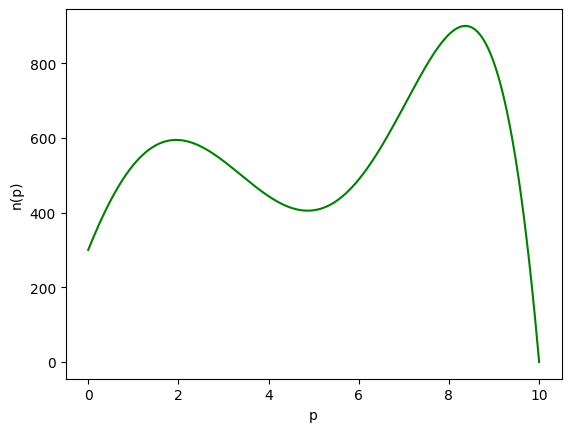

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# 100 linearly spaced numbers
x = np.linspace(0,10,1000)

# our function
y = 300 + 300*x - 60*x**2  - 17.5*x**3 + 5.32*x**4 - 0.33*x**5

#print(y)

# setting the axes at the centre
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')

# labels
plt.xlabel('p')
plt.ylabel('n(p)')

# plot the function
plt.plot(x,y, 'g')

# show the plot
plt.show()

## Con of nonlinear optimization: you may not know whether your solution is optimal!


The first solution was a **local optimum**, whereas the second one is a **global optimum**. However, we could not tell a priori whether the first solution was only a local optimum. In this example, we know that the second solution is not only a local optimum, but also a global optimum. In general, though, we cannot check that, and this is why nonlinear models are challenging to solve (even though they are usually easier to model).

## Remember the recommendations:
* Don't forget to initialize the decision variables (as you can see, the initial value matters)
* Try different initialization values when solving nonlinear optimization problems


## Bounding the decision variables
Let's add another experiment where we put bounds on the decision variables - it will help bound the solution and will fit faster, but you may miss the optimal solution.

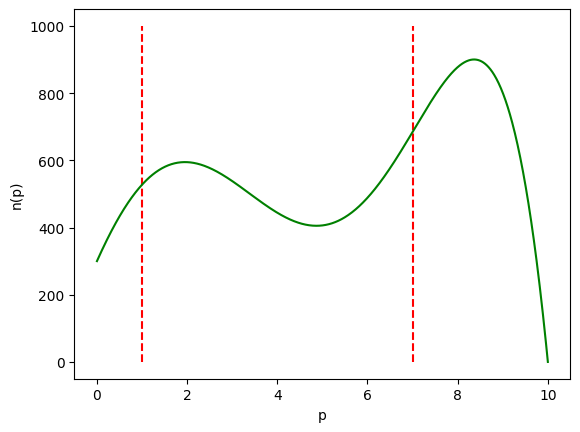

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# 100 linearly spaced numbers
x = np.linspace(0,10,1000)

# our function
y = 300 + 300*x - 60*x**2  - 17.5*x**3 + 5.32*x**4 - 0.33*x**5

#print(y)

# setting the axes at the centre
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')

# labels
plt.xlabel('p')
plt.ylabel('n(p)')

# vertical lines for simulated bounds
# we will use 1 and 7
plt.vlines(x=1, ymin=0, ymax=1000, color='red', linestyles='dashed')
plt.vlines(x=7, ymin=0, ymax=1000, color='red', linestyles='dashed')

# plot the function
plt.plot(x,y, 'g')

# show the plot
plt.show()

And here's how we would put bounds on the decision variables. You can also mess with the initial values.

In [10]:
# declare the model
model = ConcreteModel()

# declare decision variables  - bounds and initial values
# try p=4 vs. p=5 and compare the results
# looks like 4.869 is roughly the decision boundary
model.p = Var(domain=NonNegativeReals, bounds=(1,7), initialize=5)

# declare objective
model.cost = Objective(
                      expr = 300 + 300*model.p - 60*model.p**2 - 17.5*model.p**3 + 5.32*model.p**4 - 0.33*model.p**5,
                      sense = maximize)

# solve it
SolverFactory('ipopt', executable='/content/bin/ipopt').solve(model).write()
# show the results
print("Objective value = ", model.cost())
print("p = ", model.p())

# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -.inf
  Upper bound: .inf
  Number of objectives: 1
  Number of constraints: 0
  Number of variables: 1
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: ok
  Message: Ipopt 3.13.2\x3a Optimal Solution Found
  Termination condition: optimal
  Id: 0
  Error rc: 0
  Time: 0.3571491241455078
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of solutions displayed: 0
Objecti

🔴
<!-- 🎙 DAVE TALKING POINTS (invisible when rendered - double-click to read):
M4.1 Video 3 - Stress-testing a nonlinear solution with Monte Carlo

- Module 1 comes back. You have two candidate solutions from two starting points - which one do you trust?
- Jitter the parameters, re-score both solutions thousands of times, and compare the DISTRIBUTIONS rather than the two single numbers.
- Point at the means side by side. The better solution is the one that holds up under uncertainty, not the one that looked best once.
- Then sampling the solution space: instead of one lucky start, sweep many starts and look at the spread of answers. Brute force logic, applied to starting points.
- CLOSE: "optimization gives you the plan, Monte Carlo tells you how much to trust it. Same division of labour as Module 2 - it just matters more now."
-->

# Uncertainty in the parameters - Monte Carlo

We found two "optimal" prices: $p = 1.95$ (594.7 units) and $p = 8.36$ (900.1 units). But the consultants'
formula is an **estimate**. What if each coefficient is off by just a little?

**This is what we shift.** The formula is

$$n(p) = a + b\,p - c\,p^2 - d\,p^3 + e\,p^4 - f\,p^5 \qquad a=300,\; b=300,\; c=60,\; d=17.5,\; e=5.32,\; f=0.33$$

In each simulated "world", every coefficient gets multiplied by its **own** random factor between 0.99 and 1.01
(off by up to 1%), for example $a \rightarrow 300 \times U(0.99,\,1.01)$. The two prices stay **fixed**; only the
formula wiggles. Then we ask: how many units does each price sell in that world?

In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# the six coefficients, with their signs, and the power of p each one multiplies
coef = {'a': 300, 'b': 300, 'c': -60, 'd': -17.5, 'e': 5.32, 'f': -0.33}
power = {'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4, 'f': 5}

# the two "optimal" prices
p1 = 1.95
p2 = 8.36

# how big is each term of n(p) at the two prices?
terms = pd.DataFrame()
for name in coef:
    terms.loc[name, 'term'] = str(coef[name]) + ' * p^' + str(power[name])
    terms.loc[name, 'at p = 1.95'] = coef[name] * p1 ** power[name]
    terms.loc[name, 'at p = 8.36'] = coef[name] * p2 ** power[name]

terms.loc['n(p) = the sum', 'term'] = ''
terms.loc['n(p) = the sum', 'at p = 1.95'] = terms['at p = 1.95'].sum()
terms.loc['n(p) = the sum', 'at p = 8.36'] = terms['at p = 8.36'].sum()
terms.round(0)

,term,at p = 1.95,at p = 8.36
a,300 * p^0,300.0,300.0
b,300 * p^1,585.0,2508.0
c,-60 * p^2,-228.0,-4193.0
d,-17.5 * p^3,-130.0,-10225.0
e,5.32 * p^4,77.0,25986.0
f,-0.33 * p^5,-9.0,-13476.0
n(p) = the sum,,595.0,900.0


**Read the table before you simulate anything.** At $p = 1.95$ every term is a few hundred. At $p = 8.36$ the terms
are in the **thousands and tens of thousands** (+25,986 and -13,476), and they almost cancel to leave 900. A 1% error
on a 26,000 term is 260 units, more than a quarter of the whole answer. So we should expect the high price to be
far more sensitive. Here is what the wiggling looks like: 30 versions of the formula, each one off by up to 1%.

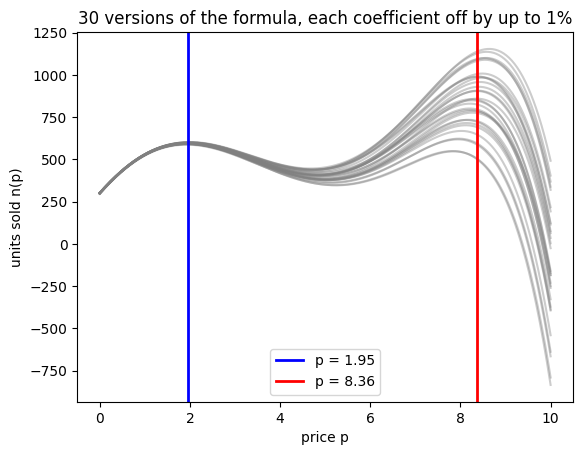

In [12]:
# 30 "worlds": each coefficient off by up to 1%
x = np.linspace(0, 10, 500)

for k in range(30):
    y = 0
    for name in coef:
        factor = np.random.uniform(0.99, 1.01)
        y = y + coef[name] * factor * x ** power[name]
    plt.plot(x, y, color='gray', alpha=0.4)

plt.axvline(p1, color='blue', linewidth=2, label='p = 1.95')
plt.axvline(p2, color='red', linewidth=2, label='p = 8.36')
plt.xlabel('price p')
plt.ylabel('units sold n(p)')
plt.title('30 versions of the formula, each coefficient off by up to 1%')
plt.legend()
plt.show()

The curves barely move at $p = 1.95$ and **fan out** at $p = 8.36$. Now do it 10,000 times and score both prices
in every world.

In [13]:
# Monte Carlo: 10,000 worlds, both prices scored in each one
error = 0.01      # each coefficient off by up to 1%
low_range = 1 - error
high_range = 1 + error

results1 = []
results2 = []

for k in range(10000):
    nn1 = 0
    nn2 = 0
    for name in coef:
        factor = np.random.uniform(low=low_range, high=high_range)
        nn1 = nn1 + coef[name] * factor * p1 ** power[name]
        nn2 = nn2 + coef[name] * factor * p2 ** power[name]
    results1.append(nn1)
    results2.append(nn2)

results1 = np.array(results1)
results2 = np.array(results2)

summary = pd.DataFrame({
    'price': ['p = 1.95', 'p = 8.36'],
    'average units': [results1.mean(), results2.mean()],
    'std. dev.': [results1.std(), results2.std()],
    'worst 5%': [np.percentile(results1, 5), np.percentile(results2, 5)],
    'best 5%': [np.percentile(results1, 95), np.percentile(results2, 95)],
})
print(summary.round(0))
print()
print("Share of worlds where the 'worse' price 1.95 actually sells more: %.1f%%" % (100 * np.mean(results1 > results2)))

      price  average units  std. dev.  worst 5%  best 5%
0  p = 1.95          595.0        4.0     588.0    601.0
1  p = 8.36          902.0      179.0     609.0   1193.0

Share of worlds where the 'worse' price 1.95 actually sells more: 3.8%


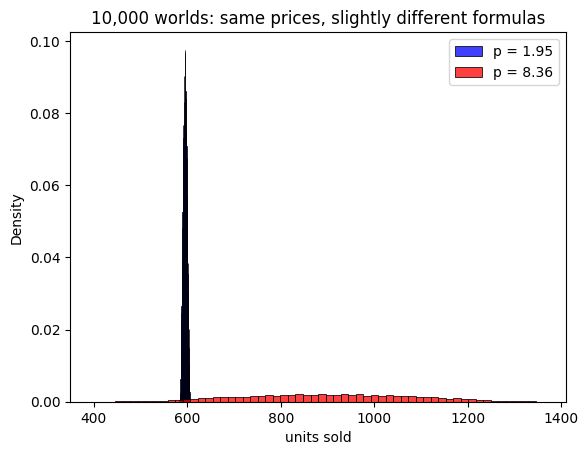

In [14]:
# both answers on one picture
sns.histplot(results1, color='blue', label='p = 1.95', stat='density', bins=60)
sns.histplot(results2, color='red', label='p = 8.36', stat='density', bins=60)
plt.xlabel('units sold')
plt.title('10,000 worlds: same prices, slightly different formulas')
plt.legend()
plt.show()

### What this tells you

- **On average**, $p = 8.36$ still wins: about 900 units against 595.
- **But it is far more fragile.** A 1% error in the coefficients moves $p = 1.95$ by a handful of units and $p = 8.36$ by
  a couple of hundred, and in a few percent of worlds the "worse" price actually sells more.
- That is the business conversation: the solver gives you the best answer **for the formula you typed in**. Monte Carlo
  tells you how much to trust it. A manager who cannot afford a bad month might take the safer price, or go back and
  get better estimates of the coefficients before betting on $p = 8.36$.

# [optional] Make a surface
On your own, you can try to make a surface and update the objective function to find the maximum of a surface in 2 dimensions

# Use Sampling to Search the Solution Space (multi-start)

Instead of guessing one starting value, try many random ones and keep the best answer. This is the
**multi-start** technique: cheap insurance against the hill climber in the fog.

*Updated October 2026:* the bounds are now (0, 10), so the random starts can actually reach the best
answer at $p = 8.36$ (with bounds of (1, 7) it was cut off), and we try 50 starts instead of 1,000 so
the cell runs in seconds.

In [15]:
import numpy as np
import pandas as pd

starts = []
found_p = []
found_units = []

for k in range(50):
    # pick a random starting value between 0 and 10
    x = np.random.uniform(low=0, high=10)

    # declare the model
    model = ConcreteModel()
    model.p = Var(domain=NonNegativeReals, bounds=(0,10), initialize=x)
    model.cost = Objective(
                          expr = 300 + 300*model.p - 60*model.p**2 - 17.5*model.p**3 + 5.32*model.p**4 - 0.33*model.p**5,
                          sense = maximize)

    # solve it (quietly - no .write() inside a loop)
    SolverFactory('ipopt', executable='/content/bin/ipopt').solve(model)

    starts.append(x)
    found_p.append(model.p())
    found_units.append(model.cost())

multistart = pd.DataFrame({'start': starts, 'p found': found_p, 'units sold': found_units})
print("I'm done! Tried", len(multistart), "random starting values.")

I'm done! Tried 50 random starting values.


p found
1.95    21
8.36    29
dtype: int64

best answer found: p = 8.36, units sold = 900.10


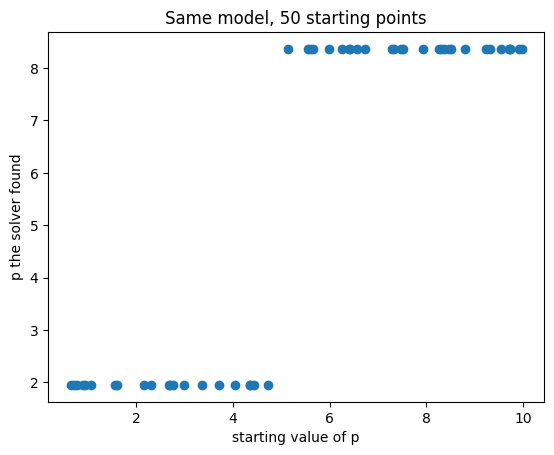

In [16]:
# where did the 50 starts end up?
print(multistart.round(2).groupby('p found').size())

best = multistart.loc[multistart['units sold'].idxmax()]
print()
print("best answer found: p = %.2f, units sold = %.2f" % (best['p found'], best['units sold']))

# each start (x axis) and the answer the solver climbed to from it (y axis)
scatter(multistart['start'], multistart['p found'])
xlabel('starting value of p')
ylabel('p the solver found')
title('Same model, 50 starting points')
show()

## Bottom line

Nonlinear programming is just optimization where the relationships bend instead of staying straight - and tons of real problems (revenue vs. price, risk vs. return) bend. **Take it further:** fit a curve to your own data and optimize on it.